# Question 1
We will now perform cross-validation on a simulated data set.

(a) Generate a simulated data set as follows:

```python
rng = np.random.default_rng(1)

x = rng.normal(size=100)

y = x - 2 * x**2 + rng.normal(size=100)
```

In this data set, what is n and what is p? Write out the model
used to generate the data in equation form.

(b) Create a scatterplot of X against Y . Comment on what you find.

(c) Set a random seed, and then compute the LOOCV errors that
result from fitting the following four models using least squares:

i. $Y = 0 + \beta_1 X + \epsilon$

ii. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \epsilon$

iii. $Y = beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$

iv. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \beta_4 X^4 + \epsilon$

Note you may find it helpful to use the data.frame() function
to create a single data set containing both X and Y .

(d) Repeat (c) using another random seed, and report your results.
Are your results the same as what you got in (c)? Why?

(e) Which of the models in (c) had the smallest LOOCV error? Is
this what you expected? Explain your answer.

All libraries exported successfully
           X          Y
0   0.345584  -0.544554
1   0.821618   0.333950
2   0.330437  -0.013532
3  -1.303157  -4.030442
4   0.905356   0.484861
..       ...        ...
95 -2.250854 -14.001012
96 -0.138655   0.932532
97  0.033000   0.198928
98 -1.425349  -4.940183
99  0.332814  -0.953841

[100 rows x 2 columns]
 In this dataset, n = 100, the number of observations 
 p = 1, because they is only one predictor


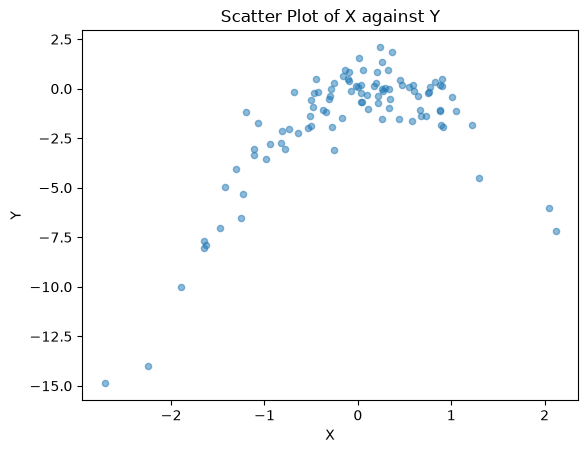

 The scatterplot seems to be showing a normal distrubution but mostly left skewed
[6.63302984 1.12293686 1.30179655 1.33239427 1.50709269]
[7.56060369 0.98403717 0.96823558 0.96595856 1.00679151]


In [2]:
#Solution 
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd 
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
Stepwise,                         
summarize ,
poly)
from sklearn.model_selection import train_test_split

from functools import partial
from sklearn.model_selection import \
(cross_validate ,
KFold ,
ShuffleSplit)
from sklearn.base import clone
from ISLP.models import sklearn_sm
print("All libraries exported successfully")

#(a) Generating data
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
data = pd.DataFrame({'X': x , 'Y' : y})
print(data)
print(" In this dataset, n = 100, the number of observations ")
print(" p = 1, because they is only one predictor")

#(b) Create a scatterplot of X against Y
scatter_plot = data.plot.scatter( "X" , "Y", alpha = 0.5)
plt.title("Scatter Plot of X against Y")
plt.show()
print(" The scatterplot seems to be showing a normal distrubution but mostly left skewed")

#(c)Set a random seed and compute LOOCV
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.linear_model import LinearRegression
data = pd.DataFrame({ "X" : x, "Y" : y})


#(c) Set a random seed and compute LOOCV errors 
data = pd.DataFrame({ "X" : x, "Y" : y})
cv_error = np.zeros(5)
H = np.array(data["X"])
Y = np.array(data["Y"])
M = sklearn_sm(sm.OLS)
for i, d in enumerate(range(1,6)):
    X = np.power.outer(H, np.arange(d+1))
    M_CV = cross_validate(M,
                          X,
                          Y,
                          cv=LeaveOneOut())
    cv_error[i] = np.mean(M_CV['test_score'])
print(cv_error)

#(d) Repeat c using another random seed and compare the results
rng = np.random.default_rng(2)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
data = pd.DataFrame({'X': x , 'Y' : y})
cv_error2 = np.zeros(5)
H = np.array(data["X"])
Y = np.array(data["Y"])
for i, d in enumerate(range(1,6)):
    X = np.power.outer(H, np.arange(d+1))
    M_CV = cross_validate(M,
                          X,
                          Y,
                          cv=LeaveOneOut())
    cv_error2[i] = np.mean(M_CV['test_score'])
print(cv_error2)


(d) The LOOCV errors are not identical because different values of x were generated

(e) The model with the lowest LOOCV in part c is model 2. This was unexpeted because I thought transforming x would decrease the errors

# Question 2 

We will now consider the Boston housing data set, from the ISLP
library.

(a) Based on this data set, provide an estimate for the population
mean of medv. Call this estimate ˆμ.

(b) Provide an estimate of the standard error of ˆμ. Interpret this
result.

Hint: We can compute the standard error of the sample mean by
dividing the sample standard deviation by the square root of the
number of observations.

(c) Now estimate the standard error of ˆμ using the bootstrap. How
does this compare to your answer from (b)?

(d) Based on your bootstrap estimate from (c), provide a 95 % confidence
interval for the mean of medv. Compare it to the results
obtained by using Boston['medv'].std() and the two standard
error rule (3.9).

Hint: You can approximate a 95 % confidence interval using the
formula [ˆμ − 2SE(ˆμ), ˆμ + 2SE(ˆμ)].

(e) Based on this data set, provide an estimate, ˆμmed, for the median
value of medv in the population.

(f) We now would like to estimate the standard error of ˆμmed. Unfortunately,
there is no simple formula for computing the standard
error of the median. Instead, estimate the standard error of the
median using the bootstrap. Comment on your findings.

In [3]:
#Solution
boston = load_data("Boston")
print(boston.head())

#(a)provide an estimate for the population mean of medv and call it mu_hat
mu_hat = boston["medv"].mean()
mu_hat = "\u03BC\u0302" + " = " + str(mu_hat)
print(mu_hat)

#(b) provide an estimate for the standard error of mu_hat. Interpret this result
n = boston.shape[0]
std_error = boston["medv"].std() / np.sqrt(n)
print(f"SE(μ̂) = {std_error}")

#(c) Standard error using bootstrap. How it compare from part b?
def boot_SE(func,
            D = boston,
            n=None,
            B=1000,
            seed=0):
    rng = np.random.default_rng(seed)
    if n is None:
        n = D.shape[0]
    boot_stats = np.zeros(B)
    for b in range(B):
        sample = D.sample(n=n, replace=True, random_state=rng)
        boot_stats[b] = func(sample)
    return boot_stats.std()     
error = boot_SE(lambda x: x["medv"].mean())
print(f"Bootstrap SE(μ̂) = {error}")

#(d)Based on c, provide a 95% confidence interval mean of medv using the fomula [ˆμ − 2SE(ˆμ), ˆμ + 2SE(ˆμ)]
formula = "ˆμ − 2SE(ˆμ), ˆμ + 2SE(ˆμ)"
mu_hat = boston["medv"].mean()
ci_lower = mu_hat - 2 * error
ci_upper = mu_hat + 2 * error
print(f"95% CI for μ: [{ci_lower}, {ci_upper}]")

#(e)Based on this data set, provide an estimate, ˆμmed, for the median value of medv in the population
mu_med = boston["medv"].median()
mu_med = "\u03BC\u0302" + " = " + str(mu_med)
print(mu_med)

#(e) Provide an estimate for the standard error of ˆμmed using bootstrap. Interpret this result
error_med = boot_SE(lambda x: x["medv"].median())
print(f"Bootstrap SE(μ̂_med) = {error_med}")


      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

   lstat  medv  
0   4.98  24.0  
1   9.14  21.6  
2   4.03  34.7  
3   2.94  33.4  
4   5.33  36.2  
μ̂ = 22.532806324110677
SE(μ̂) = 0.40886114749753505
Bootstrap SE(μ̂) = 0.4125347675099613
95% CI for μ: [21.707736789090752, 23.3578758591306]
μ̂ = 21.2
Bootstrap SE(μ̂_med) = 0.3694462207141924


For part c, the standard error is not very much different from be, they are likely the same. 

# Question 3
In this exercise, we will generate simulated data, and will then use this data to perform forward and backward stepwise selection.

(a) Create a random number generator and use its normal() method
to generate a predictor X of length n = 100, as well as a noise
vector " of length n = 100.

(b) Generate a response vector Y of length n = 100 according to
the model

$Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$

where $ \beta_0, \beta_1, \beta_2, and \beta_3$ are constants of your choice.

(c) Use forward stepwise selection in order to select a model containing
the predictors X,X2, . . . ,X10. What is the model obtained
according to Cp? Report the coefficients of the model obtained.

(d) Repeat (c), using backwards stepwise selection. How does your
answer compare to the results in (c)?

(e) Now fit a lasso model to the simulated data, again using X,X2,
. . . ,X10 as predictors. Use cross-validation to select the optimal
value of !. Create plots of the cross-validation error as a function
of !. Report the resulting coefficient estimates, and discuss the
results obtained.

In [6]:
#Solution
#(a)Create a random number generator and use its normal() method to generate a predictor X of length n = 100, as well as a noise vector " of length n = 100.
random_gen = np.random.default_rng(1)
X = random_gen.normal(size=100)
noise = random_gen.normal(size=100) 
print("Predictor X: ", X)
print("Noise vector: ", noise)

#(b)Generate a response vector Y of length n = 100 according to the model
response_vector = 1 + 2 * X - 3 * X**2 + 4 * X**3 + noise
print("Response vector Y: ", response_vector)

#(c)Use forward stepwise selection in order to select a model containing the predictors X,X2, . . . ,X10. What is the model obtained
#according to Cp? Report the coefficients of the model obtained
poly = pd.DataFrame({
f'X{i}': X**i for i in range(1, 11)
})
poly.head()

from ISLP.models import Stepwise
from ISLP.models import sklearn_selected
design = MS(poly.columns).fit(poly)
strategy = Stepwise(
	design,
	direction='forward'
)
X_design = design.transform(poly)
mod = sklearn_selected(sm.OLS, strategy)
n_obs = len(response_vector)

# Estimate error variance from the full model
full_X = sm.add_constant(poly, has_constant="add")
full_fit = sm.OLS(response_vector, full_X).fit()
sigma2 = full_fit.mse_resid

selected = []
best_cp = np.inf
mod = None
best_terms = None

# Forward selection and adding the term giving the lowest Cp at each step
for _ in range(len(poly.columns)):
    candidates = []
    for term in poly.columns:
        if term not in selected:
            terms = selected + [term]
            candidate_X = sm.add_constant(poly[terms], has_constant="add")
            fit = sm.OLS(response_vector, candidate_X).fit()
            p = int(fit.df_model) + 1 
            cp = fit.ssr / sigma2 - n_obs + 2 * p
            candidates.append((cp, term, fit, terms))

    cp, term, fit, terms = min(candidates, key=lambda item: item[0])
    selected.append(term)

    if cp < best_cp:
        best_cp = cp
        mod = fit
        best_terms = terms

print("Selected terms:", best_terms)
print(f"Minimum Cp: {best_cp:.3f}")
print(mod.params)
print(mod.summary())
print(summarize(mod))

#(d) Repeat c using backward selection, how does the answer compare
backward_terms = list(poly.columns)
backward_fit = full_fit
backward_p = int(backward_fit.df_model) + 1
best_backward_cp = backward_fit.ssr / sigma2 - n_obs + 2 * backward_p
best_backward_fit = backward_fit
best_backward_terms = backward_terms.copy()

while backward_terms:
    candidates = []
    for term in backward_terms:
        terms = [t for t in backward_terms if t != term]
        candidate_X = sm.add_constant(poly[terms], has_constant="add")
        candidate_fit = sm.OLS(response_vector, candidate_X).fit()
        p = int(candidate_fit.df_model) + 1
        cp = candidate_fit.ssr / sigma2 - n_obs + 2 * p
        candidates.append((cp, candidate_fit, terms))

    cp, candidate_fit, terms = min(candidates, key=lambda item: item[0])
    backward_terms = terms

    if cp < best_backward_cp:
        best_backward_cp = cp
        best_backward_fit = candidate_fit
        best_backward_terms = terms.copy()

print("Selected terms:", best_backward_terms)
print(f"Minimum Cp: {best_backward_cp:.3f}")
print(best_backward_fit.params)
print(best_backward_fit.summary())
print(summarize(best_backward_fit))


#(e)Fit a lasso model to the simulated data, using X1, X2, ....X10 as predictors. 
#Use cross validation for optimal selection of !
#Create plots of cross validation as a function of !. Report coeffs estimates
from sklearn.linear_model import LassoCV
X_poly = sm.add_constant(poly, has_constant="add")
lasso_cv = LassoCV(cv=10, random_state=1)
lasso_cv.fit(X_poly, response_vector)
best_lambda = lasso_cv.alpha_
print(best_lambda)
print("Coefficients of the Lasso model:")
lasso_coefficients = pd.Series(lasso_cv.coef_, index=X_poly.columns)
print(lasso_coefficients)










Predictor X:  [ 3.45584192e-01  8.21618144e-01  3.30437076e-01 -1.30315723e+00
  9.05355867e-01  4.46374572e-01 -5.36953235e-01  5.81118104e-01
  3.64572396e-01  2.94132497e-01  2.84222413e-02  5.46712987e-01
 -7.36454087e-01 -1.62909948e-01 -4.82119313e-01  5.98846213e-01
  3.97221075e-02 -2.92456751e-01 -7.81908462e-01 -2.57192241e-01
  8.14218052e-03 -2.75602905e-01  1.29406381e+00  1.00672432e+00
 -2.71116248e+00 -1.88901325e+00 -1.74772092e-01 -4.22190412e-01
  2.13642997e-01  2.17321931e-01  2.11783876e+00 -1.11202076e+00
 -3.77605007e-01  2.04277161e+00  6.46702996e-01  6.63063372e-01
 -5.14006372e-01 -1.64807517e+00  1.67464744e-01  1.09014088e-01
 -1.22735205e+00 -6.83226662e-01 -7.20436797e-02 -9.44751623e-01
 -9.82699679e-02  9.54830275e-02  3.55862371e-02 -5.06291658e-01
  5.93748072e-01  8.91166954e-01  3.20848305e-01 -8.18230227e-01
  7.31652284e-01 -5.01440018e-01  8.79160618e-01 -1.07178742e+00
  9.14467203e-01 -2.00634546e-02 -1.24874889e+00 -3.13899472e-01
  5.4102278

/tmp/ipykernel_1524/1052744000.py:22: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  design = MS(poly.columns).fit(poly)


Selected terms: ['X1', 'X2', 'X3', 'X8']
Minimum Cp: 3.671
const    1.068365
X1       1.784801
X2      -3.286965
X3       4.102171
X8       0.001991
dtype: float64
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     6052.
Date:                Fri, 20 Nov 2026   Prob (F-statistic):          2.03e-113
Time:                        03:44:19   Log-Likelihood:                -135.44
No. Observations:                 100   AIC:                             280.9
Df Residuals:                      95   BIC:                             293.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t   

/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.651400e+01, tolerance: 2.210e+00
  model = cd_fast.enet_coordinate_descent_gram(
/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.144591e+00, tolerance: 2.210e+00
  model = cd_fast.enet_coordinate_descent_gram(
/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features o

# Comments on d
The results from forward and backward selection are similar, but the specific terms selected differ. Both methods aim to minimize Cp, but they approach the selection process differently.



# Question 4 
In this exercise, we will predict the number of applications received
using the other variables in the College data set.

(a) Split the data set into a training set and a test set.

(b) Fit a linear model using least squares on the training set, and
report the test error obtained.

(c) Fit a ridge regression model on the training set, with ! chosen
by cross-validation. Report the test error obtained.

(d) Fit a lasso model on the training set, with ! chosen by crossvalidation.
Report the test error obtained, along with the number
of non-zero coefficient estimates

(e) Fit a PLS model on the training set, with M chosen by crossvalidation.
Report the test error obtained, along with the value
of M selected by cross-validation.

(f) Comment on the results obtained. How accurately can we predict
the number of college applications received? Is there much
difference among the test errors resulting from these five approaches?

In [ ]:
#Solution 
college = load_data("College")
college

#(a)Split the data into training set and test set 
from sklearn.model_selection import train_test_split
train, test = train_test_split(college, test_size=0.2, random_state=42)
print(train.shape, test.shape)

#(b)fit a linear model using least square on training set, and report test error
college_mm = MS(['Accept'])
X_train = college_mm.fit_transform(train)
y_train = train['Apps']
model = sm.OLS(y_train, X_train)
results = model.fit()
print(results.summary())

#The error 
X_test = college_mm.fit_transform(test)
y_test = test['Apps']
y_pred = results.predict(X_test)
test_error = ((y_test - y_pred) ** 2).mean()
print("Test Error:", test_error)

#(c)Fit a ridge regression model on the training set, with ! chosen by cross-validation. Report the test error obtained.
X_train_sklearn = X_train.drop(columns='intercept')
X_test_sklearn = X_test.drop(columns='intercept')

from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1)
ridge.fit(X_train_sklearn, y_train)
y_pred = ridge.predict(X_test_sklearn)
print("Ridge Regression Coefficients:", ridge.coef_)
print("Ridge Regression Intercept:", ridge.intercept_)

#The error
ridge_pred = ridge.predict(X_test_sklearn)
ridge_mse = np.mean((y_test - ridge_pred)**2)
print(ridge_mse)

#(d)Fit a Lasso model on the training set, with ! chosen by cross-validation. Report the test error obtained.
from sklearn.linear_model import LassoCV
lasso_cv = LassoCV(
alphas=10**np.linspace(8, -2, 100),
cv=10,
random_state=1
)
lasso_cv.fit(X_train_sklearn, y_train)
print("Best alpha (Lasso):", lasso_cv.alpha_)
print("Lasso Regression Coefficients:", lasso_cv.coef_)
print("Lasso Regression Intercept:", lasso_cv.intercept_)

#The error
test_error_lasso = ((y_test - lasso_cv.predict(X_test_sklearn)) ** 2).mean()
print("Test Error (Lasso):", test_error_lasso)

#(e)Fit a PLS model with M chosen by cross-validation. Report the test error obtained.
from sklearn.cross_decomposition import PLSRegression
best_M = 1
pls = PLSRegression(n_components=best_M)
pls.fit(X_train_sklearn, y_train)
print("Best number of components (PLS):", best_M)
print("PLS Regression Coefficients:", pls.coef_)
print("PLS Regression Intercept:", pls.intercept_)

#The error
pls_pred = pls.predict(X_test_sklearn).ravel()
test_error_pls = ((y_test.to_numpy() - pls_pred) ** 2).mean()
print("Test Error (PLS):", test_error_pls)


(621, 18) (156, 18)
                            OLS Regression Results                            
Dep. Variable:                   Apps   R-squared:                       0.902
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     5701.
Date:                Fri, 20 Nov 2026   Prob (F-statistic):          1.70e-314
Time:                        01:01:31   Log-Likelihood:                -5297.5
No. Observations:                 621   AIC:                         1.060e+04
Df Residuals:                     619   BIC:                         1.061e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    -40.0668     63.042

/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/base.py:969: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)
/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/base.py:969: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that bui

# Question E
They is not much difference from all the approaches that were used to find the test errors. Meaning that regularization did not predictive perfomance. I would say we were not acurate at predicting the college applications  